# Leer una fotografía RGB

Una imagen ráster organiza una escena en filas y columnas de píxeles. En una foto RGB, cada posición de esa cuadrícula guarda tres valores: rojo, verde y azul. La pantalla combina esos valores para formar el color que vemos.

`superficie → píxeles → (rojo, verde, azul)`

La misma cuadrícula sirve para mirar la foto completa, un píxel y cada canal por separado.

### Metadata de la imagen

In [13]:
from pathlib import Path
from PIL import Image, ExifTags

ruta = Path("../assets/geospatial/DCIM/DJI_202511151449_001_ellauquen-Lote1/DJI_20251115145153_0001_D.JPG")
if not ruta.exists():
    ruta = Path("assets/geospatial/DCIM/DJI_202511151449_001_ellauquen-Lote1/DJI_20251115145153_0001_D.JPG")


with Image.open(ruta) as imagen:
    print("Dimensiones:", imagen.size)
    print("Modo:", imagen.mode)

    metadatos = imagen.getexif()

    for codigo, valor in metadatos.items():
        nombre = ExifTags.TAGS.get(codigo, codigo)
        print(nombre, ":", valor)

Dimensiones: (5280, 3956)
Modo: RGB
GPSInfo : 734
ResolutionUnit : 2
ExifOffset : 260
ImageDescription : default
Make : DJI
Model : M3M
Software : 11.07.00.28
Orientation : 1
DateTime : 2025:11:15 14:51:53
YCbCrPositioning : 2
XResolution : 72.0
YResolution : 72.0
XPComment : b'0\x00.\x009\x00.\x001\x004\x002\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'
XPKeywords : b's\x00i\x00n\x00g\x00l\x00e\x00'


## La imagen como matriz

Pillow abre la fotografía y NumPy la representa como una matriz. Sus dimensiones tienen este orden: alto, ancho y cantidad de canales.

In [14]:
import matplotlib.pyplot as plt
import numpy as np

ruta = Path("../assets/geospatial/DCIM/DJI_202511151449_001_ellauquen-Lote1/DJI_20251115145153_0001_D.JPG")
if not ruta.exists():
    ruta = Path("assets/geospatial/DCIM/DJI_202511151449_001_ellauquen-Lote1/DJI_20251115145153_0001_D.JPG")

with Image.open(ruta) as foto:
    imagen = np.array(foto.convert("RGB"))

alto, ancho, cantidad_canales = imagen.shape
print(f"Dimensiones: {ancho} × {alto} píxeles")
print(f"Forma de la matriz: {imagen.shape}")
print(f"Canales: {cantidad_canales} (rojo, verde y azul)")

Dimensiones: 5280 × 3956 píxeles
Forma de la matriz: (3956, 5280, 3)
Canales: 3 (rojo, verde y azul)


El resultado `(3956, 5280, 3)` se lee como 3956 filas, 5280 columnas y 3 valores por píxel. Las dimensiones describen el tamaño digital de la foto; no indican cuánto terreno representa cada píxel. Para conocer esa resolución espacial hacen falta datos de captura y escala.

## Los tres valores de un píxel

En NumPy, `imagen[fila, columna]` busca una posición de la cuadrícula y devuelve sus valores rojo, verde y azul. La fila y la columna ubican el píxel dentro del archivo, no son coordenadas geográficas. El centro se usa aquí como una posición fácil de localizar.

Fila: 1978, columna: 2640
Rojo: 186, verde: 176, azul: 149


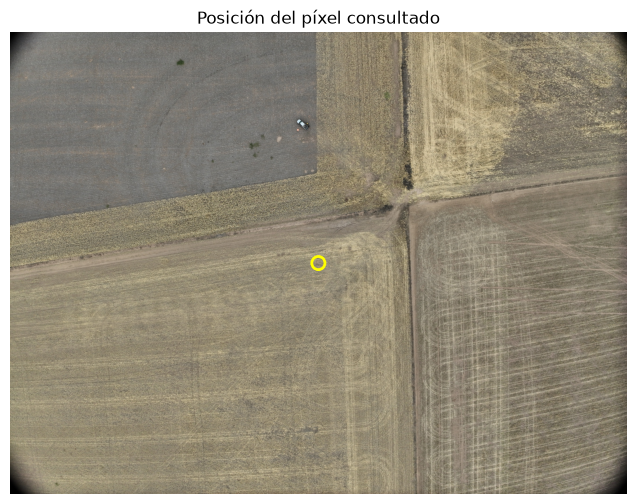

In [15]:
fila = alto // 2
columna = ancho // 2
rojo, verde, azul = imagen[fila, columna]

print(f"Fila: {fila}, columna: {columna}")
print(f"Rojo: {rojo}, verde: {verde}, azul: {azul}")

figura, eje = plt.subplots(figsize=(9, 6))
eje.imshow(imagen)
eje.scatter(columna, fila, s=90, facecolors="none", edgecolors="yellow", linewidths=2)
eje.set_title("Posición del píxel consultado")
eje.axis("off")
plt.show()

## Una capa para cada canal

`imagen[:, :, 0]` reúne los valores rojos de todos los píxeles; los índices `1` y `2` reúnen los verdes y azules. Cada canal es otra matriz sobre las mismas filas y columnas. En escala de grises, los tonos claros indican valores más altos de ese canal y los oscuros, valores más bajos.

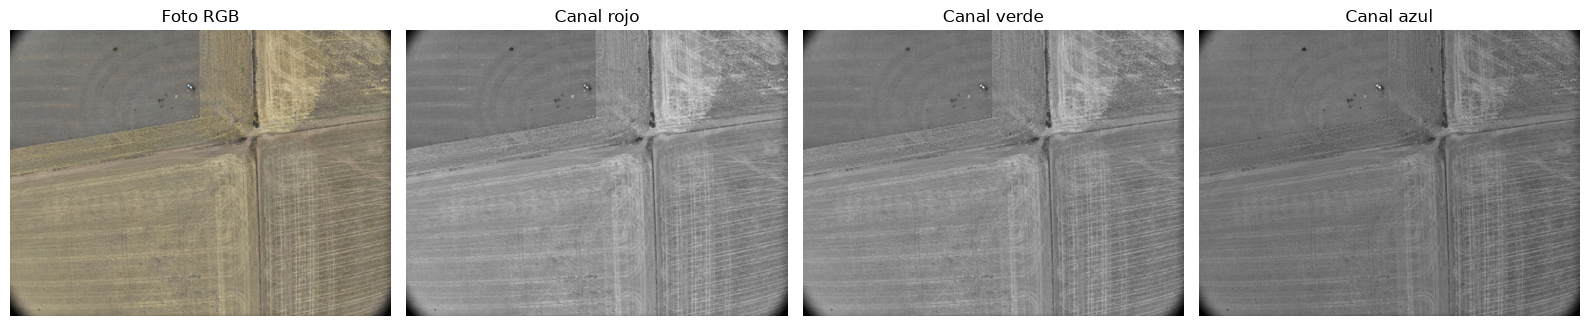

In [16]:
figura, ejes = plt.subplots(1, 4, figsize=(16, 4))

ejes[0].imshow(imagen)
ejes[0].set_title("Foto RGB")
ejes[1].imshow(imagen[:, :, 0], cmap="gray", vmin=0, vmax=255)
ejes[1].set_title("Canal rojo")
ejes[2].imshow(imagen[:, :, 1], cmap="gray", vmin=0, vmax=255)
ejes[2].set_title("Canal verde")
ejes[3].imshow(imagen[:, :, 2], cmap="gray", vmin=0, vmax=255)
ejes[3].set_title("Canal azul")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()

Una composición RGB muestra tres componentes de color visible. El JPEG fue procesado para mostrar color en pantalla: sus valores no son reflectancia calibrada. Un sensor multibanda puede registrar otras regiones, como el infrarrojo cercano, pero esa información no aparece en esta foto RGB.

## Una máscara gruesa por textura

En esta foto, los tonos del suelo y de las coberturas secas se parecen; buscar solo píxeles verdes no separa bien el camino de las hileras. Una pista visual es la **textura**: los surcos producen cambios de brillo dentro de un bloque, mientras que el tramo horizontal del camino es más uniforme.

El código promedia los tres valores RGB para obtener un brillo sencillo. Después agrupa la matriz en bloques de 64 × 64 píxeles y calcula la desviación estándar del brillo en cada bloque: un valor alto indica mayor variación. El `reshape` convierte cada bloque en una celda de un ráster más grueso; una celda reúne 64 × 64 píxeles originales. El umbral 30 resalta variación marcada en esta foto, y el bloque no representa una cantidad conocida de metros.

Bloques resaltados por textura: 5.1%


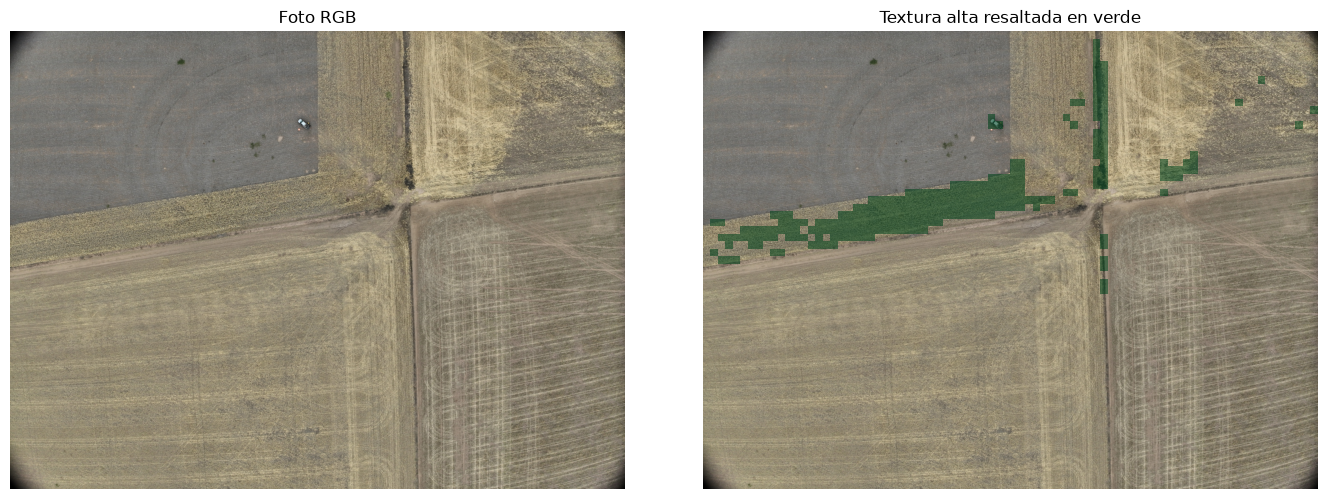

In [17]:
tamano_bloque = 64
alto_util = alto - alto % tamano_bloque
ancho_util = ancho - ancho % tamano_bloque

brillo = imagen[:alto_util, :ancho_util].mean(axis=2)
bloques = brillo.reshape(
    alto_util // tamano_bloque, tamano_bloque,
    ancho_util // tamano_bloque, tamano_bloque
)
textura = bloques.std(axis=(1, 3))
umbral_textura = 30
textura_alta = textura > umbral_textura

figura, ejes = plt.subplots(1, 2, figsize=(14, 5))
ejes[0].imshow(imagen[:alto_util, :ancho_util])
ejes[0].set_title("Foto RGB")
ejes[1].imshow(imagen[:alto_util, :ancho_util])
resalte = np.ma.masked_where(~textura_alta, textura_alta)
ejes[1].imshow(
    resalte, cmap="Greens", alpha=0.55, interpolation="nearest",
    extent=(0, ancho_util, alto_util, 0), vmin=0, vmax=1
)
ejes[1].set_title("Textura alta resaltada en verde")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
print(f"Bloques resaltados por textura: {textura_alta.mean() * 100:.1f}%")

La franja de hileras aparece resaltada y la mayor parte del camino horizontal queda fuera de la máscara. El porcentaje impreso es la proporción de bloques con textura alta, no la proporción de terreno cultivado. Bordes, sombras y suelo irregular pueden resaltarse por error; un cultivo seco o uniforme puede quedar sin marcar. La regla clasifica textura, no reconoce cultivos.

## Resumir y comparar intensidades

El promedio reúne los valores de todos los píxeles de un canal en un solo número. Sirve para describir la intensidad general del canal, pero pierde la ubicación de cada valor y mezcla suelo, vegetación, sombras y otros elementos.

In [18]:
nombres = ["Rojo", "Verde", "Azul"]
for indice, nombre in enumerate(nombres):
    promedio = imagen[:, :, indice].mean()
    print(f"{nombre}: {promedio:.1f} de 255")

Rojo: 140.6 de 255
Verde: 132.2 de 255
Azul: 113.0 de 255


El histograma conserva más detalle que el promedio: cuenta cuántos píxeles caen en distintos intervalos de intensidad. En el eje horizontal está el valor del canal (de 0 a 255); en el vertical, la cantidad de píxeles. Cada barra resume un intervalo, no una zona particular del terreno.

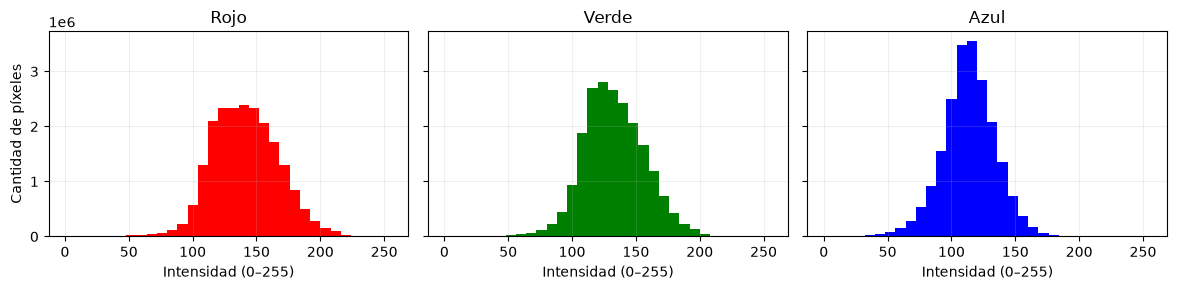

In [19]:
colores = ["red", "green", "blue"]
figura, ejes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)

for indice, eje, nombre, color in zip(range(3), ejes, nombres, colores):
    valores = imagen[:, :, indice].ravel()
    eje.hist(valores, bins=32, range=(0, 256), color=color)
    eje.set_title(nombre)
    eje.set_xlabel("Intensidad (0–255)")
    eje.grid(alpha=0.2)

ejes[0].set_ylabel("Cantidad de píxeles")
plt.tight_layout()

## Qué podemos concluir

La foto permite comparar cómo varían los tres canales de color y observar patrones de la escena. Los promedios y los histogramas describen valores digitales, no dicen qué objeto produjo cada valor. Por eso no identifican cultivos o malezas, no miden reflectancia calibrada y no convierten las dimensiones del archivo en metros por píxel. Para esas interpretaciones hacen falta contexto y metadatos adecuados.